### ArcGIS Pro Data Prep & Transformation

Prior to data analysis within the Python notebook, I used ARCGIS Pro to perform data preparation, terrain and sampling, and mapping functions. 

In the following cells, I outline the steps taken to perform the analysis.

#### Data Cleaning

**Positional accuracy filter**
iNaturalist records include a positional_accuracy value, which represents the estimated radius (in meters) of uncertainty around each observation's coordinates. Some observations are uncertain by hundreds of meters or several kilometers. This project compares each observation to a 10 m elevation model, and Salt Lake County has steep terrain along the Wasatch front, so a location error that large can place a point on a very different elevation, slope, or aspect than where the plant actually grew.

To prepare for data analysis, I removed observations with no accuracy value and observations with a positional accuracy of 100 m or more. The reliability of the observations with no positional value are difficult to assess. The 100 meter cutoff was a judgment call, driven by the assumption that slope, elevation, and aspect can vary greatly within the foothills and canyons of Salt Lake County. 

**Result**
- Total Research Grade observations exported: 817
- Blank positional accuracy value: 112
- Removed (accuracy over 100 m or blank): 222
- Kept for analysis: 595

**Limitation**
A stricter or looser cutoff would change the sample size and could shift the results. Potential follow up: assess how sensitive the findings are to a 50 m or 250 m threshold.

#### Turn the observations into a map layer

The cleaned CSV is a table of coordinates, so I converted it to a point layer with XY Table To Point (X = longitude, Y = latitude, coordinate system WGS 1984). 
I then used Project to move the points into NAD 1983 UTM Zone 12N, the coordinate system used for the rest of the analysis. UTM is measured in meters, which makes distance and slope calculations accurate. 
Finally, I used Clip to keep only points inside the Salt Lake County boundary.

**Output:** obs_SLC, 595 observation points in UTM 12N.

#### Prepare the county boundary

The boundary came from the U.S. Census Bureau cartographic boundary file (sb_2025_us_cousub_500k). I selected records where COUNTYFP = 035 and exported it as its own layer. Then projected it to UTM 12N so it matches the elevation data and observation points.

**Output:** saltlakecounty_utm12, the study area outline (about 1,949 km² of land area (excluding water area).

#### Prepare the elevation data

The elevation data is the Utah Geospatial Resource Center's 10 m DEM (derived from USGS 3DEP), which is already in UTM 12N. I merged 2 tiles with Mosaic To New Raster.] Then used Extract by Mask with the county boundary to clip the DEM to Salt Lake County, so that every later calculation only covers the study area.

**Output:** DEM_SLCounty, a 10 m elevation raster for the county.

#### Calculate slope and aspect

I ran Slope (in degrees) and Aspect on the clipped DEM. 
Slope and aspect describe the ground at each location: how steep it is, and which direction it faces. 
Perfectly flat cells get an aspect of -1 because they have no direction.

**Outputs:** slope_SLC and aspect_SLC.

#### Create background points

iNaturalist records show where the plant was seen, not where it is absent, and people tend to photograph near trails and neighborhoods. 
To compare observed conditions against the county as a whole, I generated 5,000 random points across the county with Create Random Points (minimum spacing 100 m). These background points show what the landscape looks like in general.

**Output:** bg_points, 5,000 random points inside the county boundary.

#### Attach terrain values to the points

I used Extract Multi Values to Points to read elevation, slope, and aspect at every observation and every background point. 
I worked on copies of each point layer because this tool adds columns directly to its input. 
I then exported both tables to CSV (spurge_values.csv and background_values.csv), which the analysis below uses.

**Outputs:** two CSVs with elevation, slope, and aspect for each point.

In [ ]:
import pandas as pd
from pathlib import Path

folder = Path(r"")

df = pd.read_csv(folder / "observations-805713.csv")
print("total records:", len(df))
print("blank accuracy:", df["positional_accuracy"].isna().sum())

clean = df[df["positional_accuracy"] <= 100]
print("kept:", len(clean), "| dropped:", len(df) - len(clean))

clean.to_csv(folder / "obs_clean.csv", index=False)

total records: 817
blank accuracy: 112
kept: 595 | dropped: 222


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("")

spurge = pd.read_csv(folder / "myrtle_spurge_values.csv")
bg = pd.read_csv(folder / "background_values.csv")

print(spurge.columns.tolist())
print("spurge rows:", len(spurge), "| background rows:", len(bg))

['id', 'uuid', 'observed_on_string', 'observed_on', 'time_observed_at', 'time_zone', 'user_id', 'created_at', 'updated_at', 'quality_grade', 'license', 'url', 'image_url', 'sound_url', 'tag_list', 'description', 'num_identification_agreements', 'num_identification_disagreements', 'captive_cultivated', 'oauth_application_id', 'place_guess', 'latitude', 'longitude', 'positional_accuracy', 'private_place_guess', 'private_latitude', 'private_longitude', 'public_positional_accuracy', 'geoprivacy', 'taxon_geoprivacy', 'coordinates_obscured', 'positioning_method', 'positioning_device', 'species_guess', 'scientific_name', 'common_name', 'iconic_taxon_name', 'taxon_id', 'DEM_SLCounty', 'slope_slc', 'aspect_SLC']
spurge rows: 593 | background rows: 5000


In [28]:
def standardize(df):
    new = {}
    for c in df.columns:
        lc = c.lower()
        if "dem" in lc or "elev" in lc:
            new[c] = "elevation"
        elif "slope" in lc:
            new[c] = "slope"
        elif "aspect" in lc:
            new[c] = "aspect"
    return df.rename(columns=new)

spurge = standardize(spurge)
bg = standardize(bg)

print(spurge.columns.tolist())
print(bg.columns.tolist())

['id', 'uuid', 'observed_on_string', 'observed_on', 'time_observed_at', 'time_zone', 'user_id', 'created_at', 'updated_at', 'quality_grade', 'license', 'url', 'image_url', 'sound_url', 'tag_list', 'description', 'num_identification_agreements', 'num_identification_disagreements', 'captive_cultivated', 'oauth_application_id', 'place_guess', 'latitude', 'longitude', 'positional_accuracy', 'private_place_guess', 'private_latitude', 'private_longitude', 'public_positional_accuracy', 'geoprivacy', 'taxon_geoprivacy', 'coordinates_obscured', 'positioning_method', 'positioning_device', 'species_guess', 'scientific_name', 'common_name', 'iconic_taxon_name', 'taxon_id', 'elevation', 'slope', 'aspect']
['CID', 'elevation', 'slope', 'aspect']


In [29]:
cols = ["elevation", "slope", "aspect"]
spurge["group"] = "Myrtle spurge"
bg["group"] = "Background"

for name, d in [("spurge", spurge), ("background", bg)]:
    print(name, "| missing values:", d[cols].isna().sum().sum(), "| flat cells (aspect = -1):", (d["aspect"] == -1).sum())

spurge = spurge.dropna(subset=cols)
bg = bg.dropna(subset=cols)

# Remove flat cells (aspect = -1) from both groups. These are mostly water and a few level areas.
spurge = spurge[spurge["aspect"] != -1]
bg = bg[bg["aspect"] != -1]

print("kept: spurge", len(spurge), "| background", len(bg))

spurge | missing values: 0 | flat cells (aspect = -1): 0
background | missing values: 13 | flat cells (aspect = -1): 143
kept: spurge 593 | background 4852


In [30]:
bins = [0, 45, 135, 225, 315, 360]
labels = ["N", "E", "S", "W", "N2"]

def add_aspect_class(df):
    df["aspect_class"] = pd.cut(df["aspect"], bins=bins, labels=labels, include_lowest=True).astype(str).replace({"N2": "N"})
    return df

spurge = add_aspect_class(spurge)
bg = add_aspect_class(bg)

data = pd.concat([spurge[cols + ["aspect_class", "group"]], bg[cols + ["aspect_class", "group"]]], ignore_index=True)
data["aspect_class"] = pd.Categorical(data["aspect_class"], categories=["N", "E", "S", "W"], ordered=True)

In [31]:
summary = data.groupby("group")[["elevation", "slope"]].quantile([0.1, 0.5, 0.9]).unstack().round(1)
display(summary)

aspect_share = (pd.crosstab(data["group"], data["aspect_class"], normalize="index") * 100).round(1)
display(aspect_share)

elevation                 slope            
                    0.1     0.5     0.9   0.1   0.5   0.9
group                                                    
Background       1287.9  1798.0  2705.6   0.4  14.9  35.9
Myrtle spurge    1370.0  1529.1  1765.3   3.2  16.9  33.0

aspect_class,N,E,S,W
group,,,,
Background,27.8,27.1,21.1,24.0
Myrtle spurge,9.8,12.5,41.3,36.4


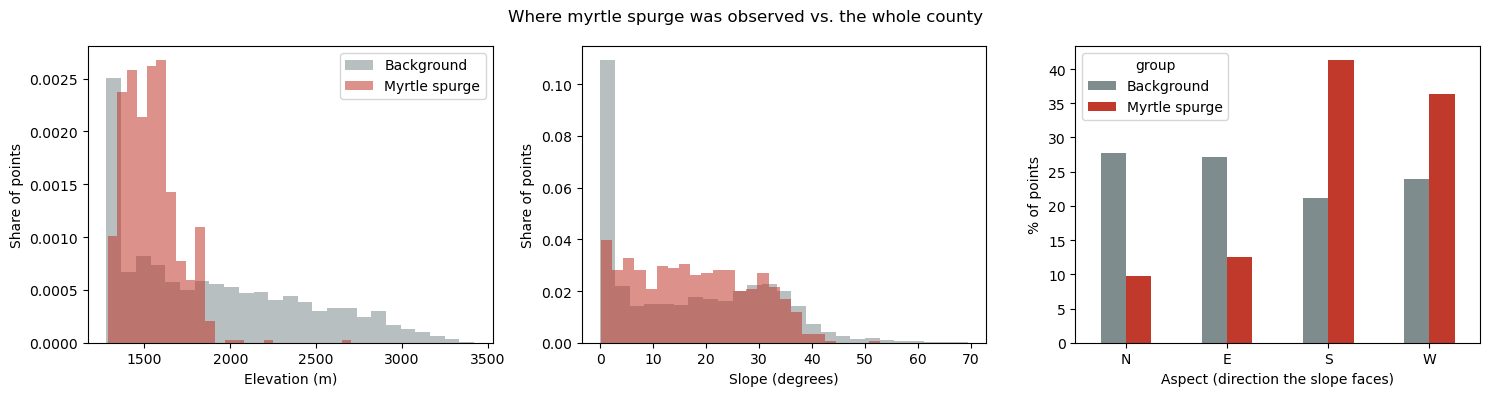

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
colors = {"Myrtle spurge": "#c0392b", "Background": "#7f8c8d"}

for var, a, title in [("elevation", ax[0], "Elevation (m)"), ("slope", ax[1], "Slope (degrees)")]:
    for g, sub in data.groupby("group"):
        a.hist(sub[var], bins=25, alpha=0.55, density=True, label=g, color=colors[g])
    a.set_xlabel(title)
    a.set_ylabel("Share of points")
ax[0].legend()

aspect_share.T.plot(kind="bar", ax=ax[2], color=[colors[c] for c in aspect_share.index], rot=0)
ax[2].set_xlabel("Aspect (direction the slope faces)")
ax[2].set_ylabel("% of points")

fig.suptitle("Where myrtle spurge was observed vs. the whole county")
plt.tight_layout()
fig.savefig(folder / "fig_habitat_comparison.png", dpi=150)
plt.show()

Observations:
- Myrtle spurge tends to be observed between ~1350m and ~1750m 
- Slope of observed myrtle spurge generally varies from 0 to 40 degrees
- Observations tend to be recorded on South and West facing slopes  


In [33]:
b = data[data["group"] == "Background"]
print("background rows:", len(b))
print("elevation in range:", round(b["elevation"].between(*elevation_range).mean(), 3))
print("slope in range:    ", round(b["slope"].between(*slope_range).mean(), 3))
print("aspect in S/W:     ", round(b["aspect_class"].isin(aspects).mean(), 3))
print(b["aspect_class"].value_counts(dropna=False))
print(b[["elevation", "slope", "aspect"]].describe().round(1))

background rows: 4852
elevation in range: 0.347
slope in range:     0.632
aspect in S/W:      0.451
aspect_class
N    1351
E    1314
W    1163
S    1024
Name: count, dtype: int64
       elevation   slope  aspect
count     4852.0  4852.0  4852.0
mean      1897.0    16.5   174.3
std        530.0    14.4   108.6
min       1278.7     0.0     0.0
25%       1409.6     1.8    77.3
50%       1798.0    14.9   169.6
75%       2284.4    29.1   273.1
max       3419.7    69.4   359.8


In [34]:
ELEV_LOW = float(spurge["elevation"].quantile(0.1))
ELEV_HIGH = float(spurge["elevation"].quantile(0.99))

SLOPE_LOW = float(spurge["slope"].quantile(0.1))
SLOPE_HIGH = float(spurge["slope"].quantile(0.99))

print(f"Elevation: {ELEV_LOW} to {ELEV_HIGH} m")
print(f"Slope: {SLOPE_LOW} to {SLOPE_HIGH} degrees")

#Opportunity to explore: review how selecting different percentiles of observations captures the most possible myrtle spurge observations without  expanding range too large
#Goal with this is to capture as much of the specific range of slope and elevation spurge is observed without opening the range too wide - want to separate the plant's habitat range 
#If time permits, loop through several options to determine best range 


Elevation: 1370.04118656 to 1909.6279297 m
Slope: 3.16877232 to 39.61741191600003 degrees


In [35]:
elevation_range = (ELEV_LOW, ELEV_HIGH)
slope_range = (SLOPE_LOW, SLOPE_HIGH)
aspects = ["S", "W"]

data["suitable"] = (
    data["elevation"].between(*elevation_range)
    & data["slope"].between(*slope_range)
    & data["aspect_class"].isin(aspects)
)
print((data.groupby("group")["suitable"].mean() * 100).round(1))

group
Background       10.4
Myrtle spurge    66.1
Name: suitable, dtype: float64


### Map suitable habitat

I defined "suitable" as the conditions where most observations occurred: 
- elevation of 1370m to 1909m m, 
- slope of 3.16 degrees to 39.62 degrees, 
- south- or west-facing aspects (135-315 degrees), based on the 10th to 99th percentile of the observed points.

I combined the three conditions in Raster Calculator so that cells meeting all three get a value of 1.

**Output:** suitable_SLC_v2, covering 218.5 km² (11.2% of the county's land area).

Note: my first version of this raster used percentile ranges calculated from all points instead of the spurge observations alone. Comparing it against the notebook's results exposed the mistake, and I rebuilt it with the correct ranges.

#### Identify priority areas

A suitable spot near a recent sighting is a more urgent place to look than a suitable spot far from any known site. 

I selected observations from 2023 onward, given  buffered them by 500 m with the Buffer tool, and used Extract by Mask to keep only the suitable cells inside that buffer.

**Outputs:** priority_SLC_v2: 40.6 km² at 500 m.